# Capítulo 5 · Actividad: ¿quién sobrevivió al Titanic?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_05/01_actividad_titanic_arbol.ipynb)

Entrena un **árbol de decisión** que prediga si un pasajero sobrevivió (`survived`) y consigue el mejor modelo que puedas. Haz todo el proceso que vimos en clase; el preprocesamiento lo decides tú.

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos: `uv run python scripts/download_data.py`

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_score, cross_validate,
                                     learning_curve, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, StandardScaler)
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Que scikit-learn devuelva DataFrames (con nombres de columna) en lugar de arrays de NumPy
set_config(transform_output="pandas")
sns.set_theme(style="whitegrid")

# Semilla para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)
# Que scikit-learn devuelva DataFrames (con nombres de columna) en lugar de arrays de NumPy
set_config(transform_output="pandas")

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

df = pd.read_csv(DATA_DIR / "titanic.csv")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [8]:
titanic = df.copy().drop(columns=["embarked","alive","class","adult_male"])
titanic.dtypes
#Los no asignados pasan a formar una nueva categoria
titanic.loc[titanic["deck"].isna(),"deck"]="NA"

#Relleno edades por medio de mediana y relleno con mediana
titanic["age"] = titanic["age"].fillna(
    titanic.groupby("who")["age"].transform("median")
)

#Asignacion de ciudad de embarque por medio de moda 
moda = titanic["embark_town"].mode()[0]    # mode() devuelve una Series: nos quedamos con el primer valor
titanic["embark_town"] = titanic["embark_town"].fillna(moda)
titanic["embark_town"].value_counts()
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,who,deck,embark_town,alone
0,0,3,male,22.0,1,0,7.2500,man,NA,Southampton,False
1,1,1,female,38.0,1,0,71.2833,woman,C,Cherbourg,False
2,1,3,female,26.0,0,0,7.9250,woman,NA,Southampton,True
3,1,1,female,35.0,1,0,53.1000,woman,C,Southampton,False
4,0,3,male,35.0,0,0,8.0500,man,NA,Southampton,True


In [9]:
print("Filas y columnas:", titanic.shape)
titanic.info()

Filas y columnas: (891, 11)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          891 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   who          891 non-null    str    
 8   deck         891 non-null    str    
 9   embark_town  891 non-null    str    
 10  alone        891 non-null    bool   
dtypes: bool(1), float64(2), int64(4), str(4)
memory usage: 70.6 KB


In [10]:
titanic.describe().round(2)

,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,891.00,891.00,891.00,891.00
mean,0.38,2.31,29.76,0.52,0.38,32.20
std,0.49,0.84,13.00,1.10,0.81,49.69
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,2.00,22.00,0.00,0.00,7.91
50%,0.00,3.00,30.00,0.00,0.00,14.45
75%,1.00,3.00,35.00,1.00,0.00,31.00
max,1.00,3.00,80.00,8.00,6.00,512.33


/tmp/ipykernel_45213/1480373292.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=titanic, x="survived", palette="Set2")


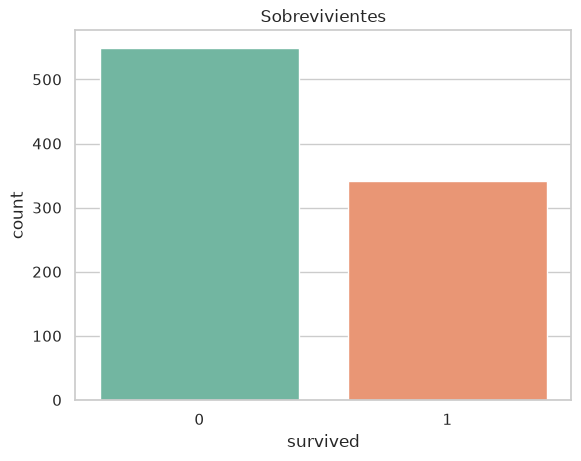

survived
0    549
1    342
Name: count, dtype: int64

In [11]:
ax = sns.countplot(data=titanic, x="survived", palette="Set2")
ax.set_title("Sobrevivientes")
plt.show()

df["survived"].value_counts()

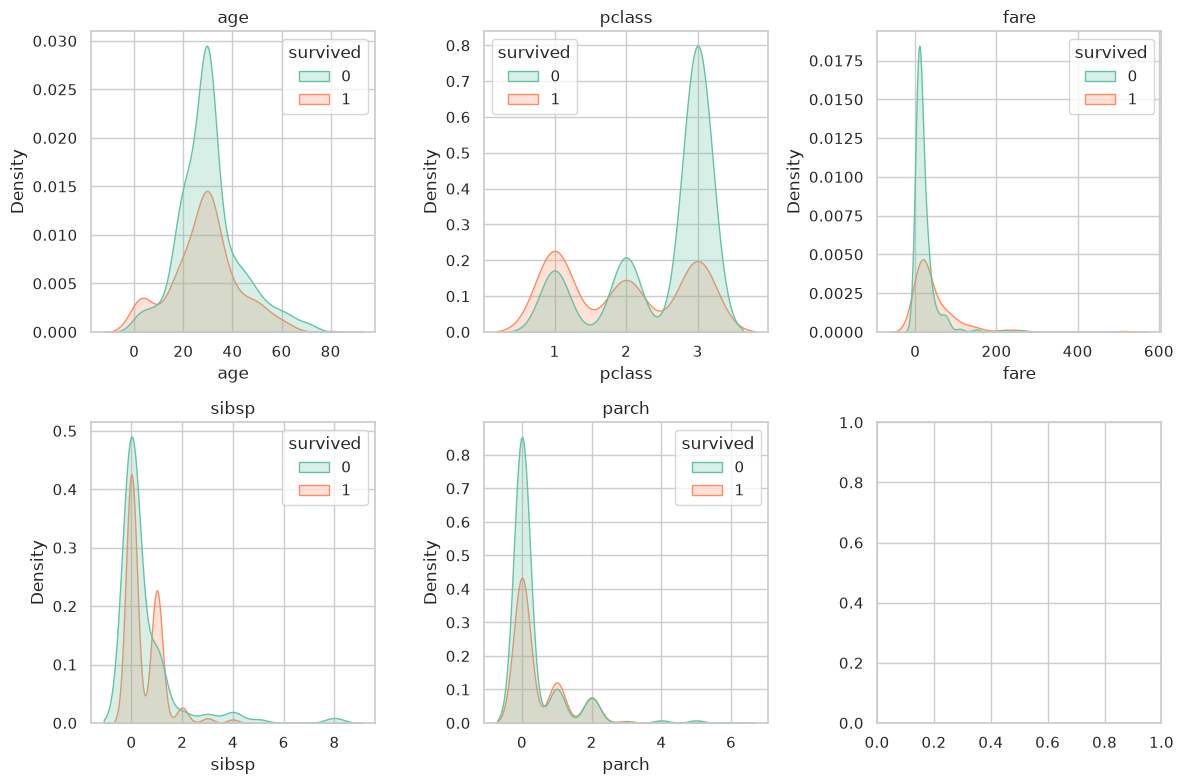

In [12]:
variables = ["age", "pclass","fare","sibsp","parch"]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for variable, ax in zip(variables, axes.flat):
    sns.kdeplot(data=titanic, x=variable, hue="survived", fill=True, palette="Set2", ax=ax)
    ax.set_title(variable)
plt.tight_layout()
plt.show()

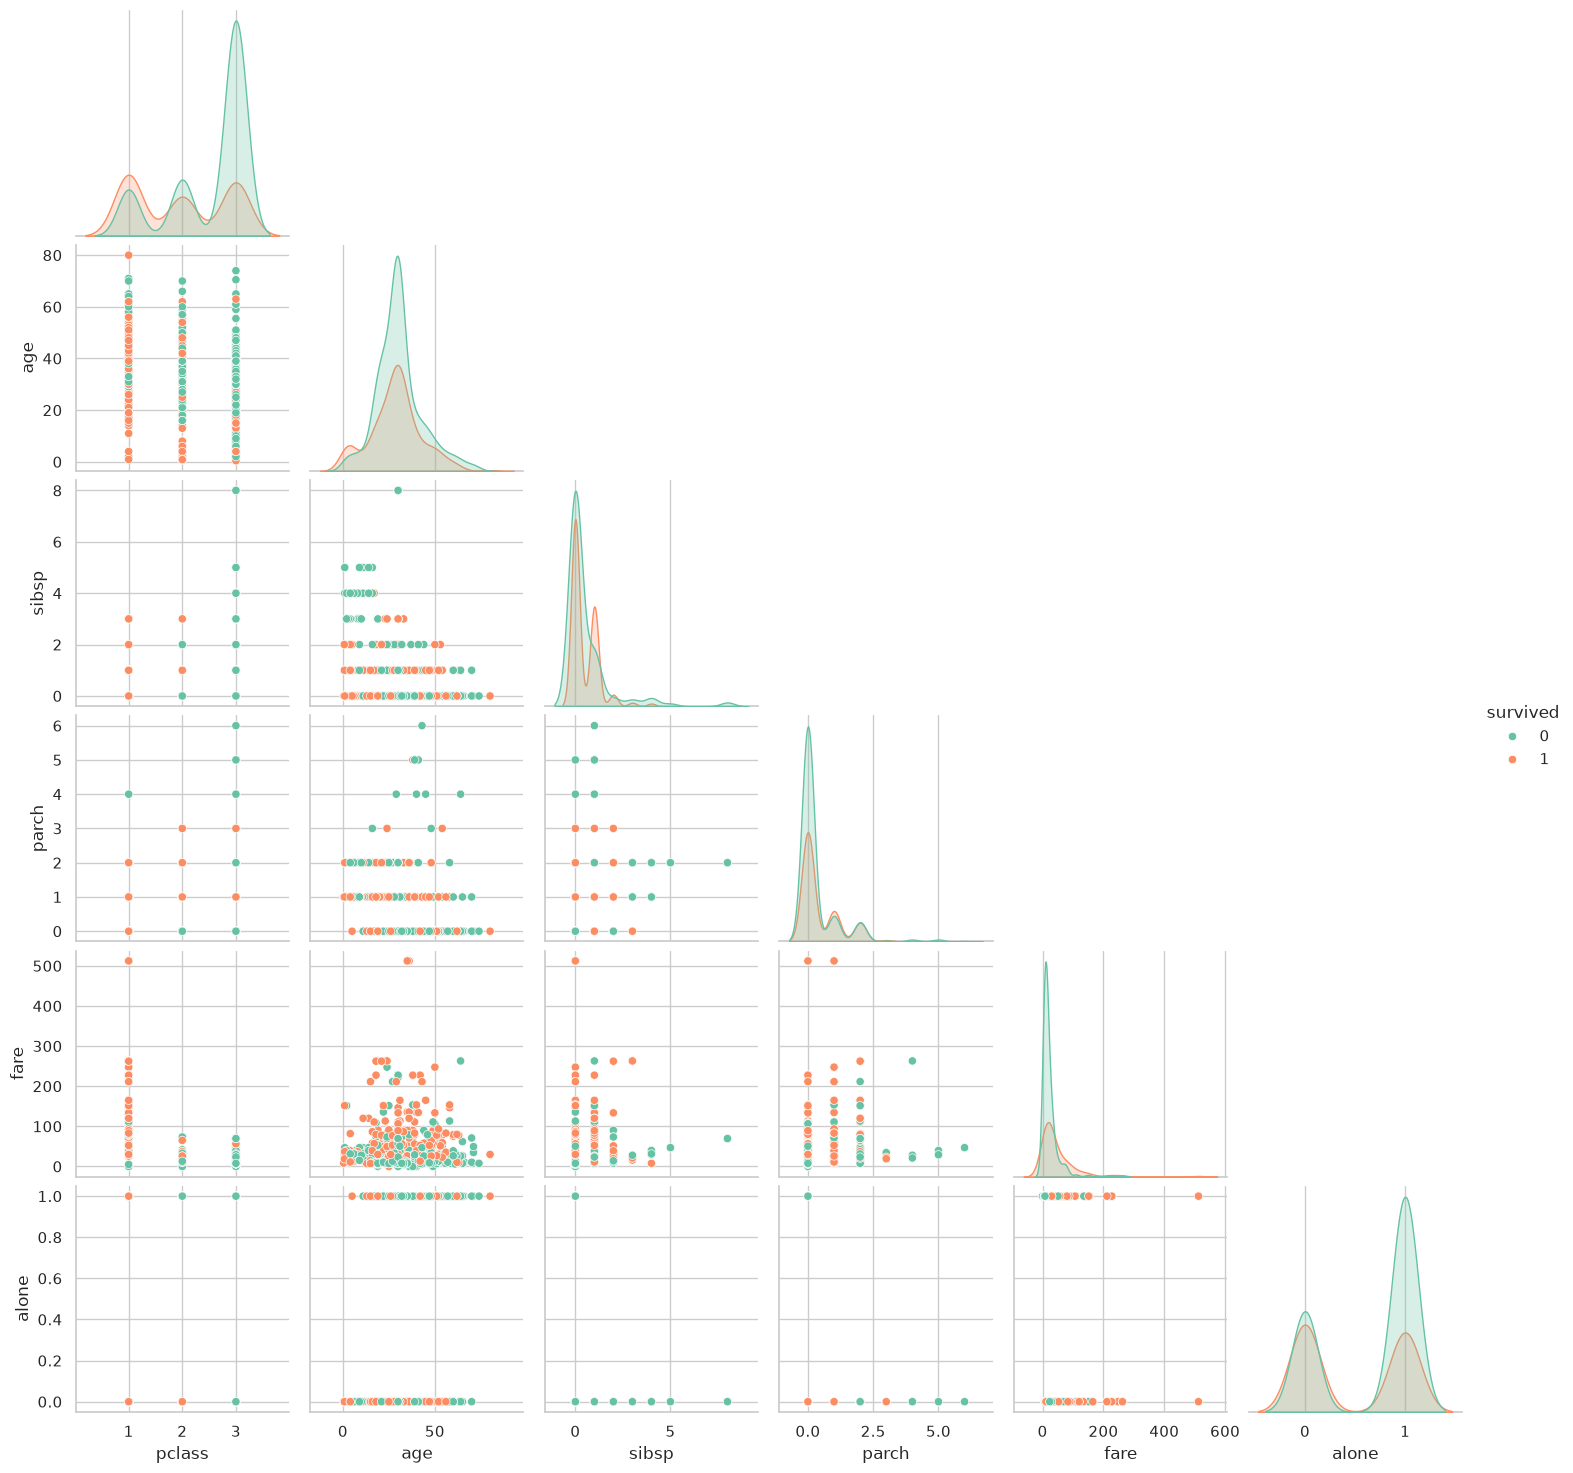

In [13]:
sns.pairplot(titanic, hue="survived", palette="Set2", corner=True)
plt.show()

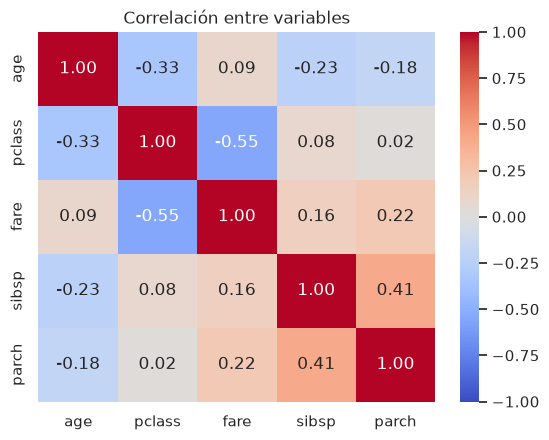

In [14]:
correlaciones = titanic[variables].corr()

sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables")
plt.show()

## Intento Pipeline

In [15]:
titanic = df.copy().drop(columns=["embarked","alive","class","adult_male"])

In [16]:
titanic.dtypes

survived         int64
pclass           int64
sex                str
age            float64
sibsp            int64
parch            int64
fare           float64
who                str
deck               str
embark_town        str
alone             bool
dtype: object

In [17]:
#Los no asignados pasan a formar una nueva categoria
titanic.loc[titanic["deck"].isna(),"deck"]="NA"

#Relleno edades por medio de mediana y relleno con mediana
titanic["age"] = titanic["age"].fillna(
    titanic.groupby("who")["age"].transform("median")
)

#Asignacion de ciudad de embarque por medio de moda 
moda = titanic["embark_town"].mode()[0]    # mode() devuelve una Series: nos quedamos con el primer valor
titanic["embark_town"] = titanic["embark_town"].fillna(moda)
titanic["embark_town"].value_counts()

embark_town
Southampton    646
Cherbourg      168
Queenstown      77
Name: count, dtype: int64

In [18]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,who,deck,embark_town,alone
0,0,3,male,22.0,1,0,7.2500,man,NA,Southampton,False
1,1,1,female,38.0,1,0,71.2833,woman,C,Cherbourg,False
2,1,3,female,26.0,0,0,7.9250,woman,NA,Southampton,True
3,1,1,female,35.0,1,0,53.1000,woman,C,Southampton,False
4,0,3,male,35.0,0,0,8.0500,man,NA,Southampton,True


In [19]:
asimetricas = ["fare"]
numericas = ["sibsp","parch","age"]
nominales = ["sex","who","deck","embark_town","alone"]
ordinales = ["pclass"]

pipeline_asimetrico= Pipeline([
    ("log",FunctionTransformer(np.log1p,feature_names_out="one-to-one")),
    ("escalar",StandardScaler())
])

preprocesador = ColumnTransformer([
    ("num",StandardScaler(),numericas),
    ("asim",pipeline_asimetrico, asimetricas),
    ("nom",OneHotEncoder(handle_unknown="ignore",drop="if_binary",sparse_output=False),nominales),
    ("ord","passthrough",ordinales)
])
preprocesador

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('asim', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_

In [20]:
X=titanic.drop(columns=["survived"])
y=titanic["survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.2, stratify=y , random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (712, 10) | Test: (179, 10)


In [21]:
X_train = preprocesador.fit_transform(X_train)
X_test=preprocesador.transform(X_test)

print("Train:", X_train.shape, "| Test:", X_test.shape)
pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()})

Train: (712, 21) | Test: (179, 21)


,train,test
survived,,
0,439,110
1,273,69


## Modelo base

In [22]:
arbol_base = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)

print("Accuracy en training:", accuracy_score(y_train, arbol_base.predict(X_train)))
print("Accuracy en test:", accuracy_score(y_test, arbol_base.predict(X_test)))

Accuracy en training: 0.9859550561797753
Accuracy en test: 0.7932960893854749


Accuracy en cada fold: [0.79  0.755 0.732 0.775 0.775]
Media: 0.765 ± 0.020


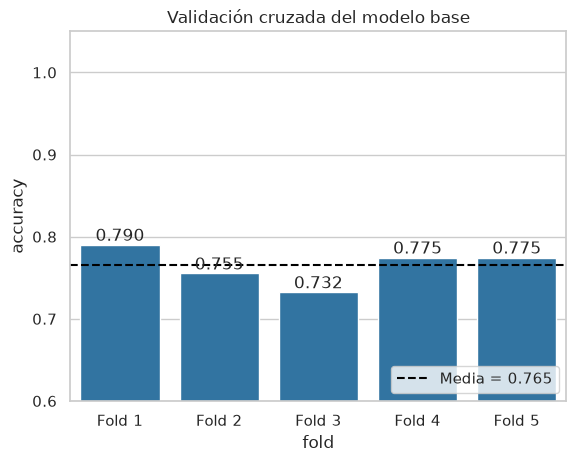

In [23]:
#Recuerda que aqui ya segmento el test
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

scores_base = cross_val_score(arbol_base, X_train, y_train, cv=cv, scoring="accuracy")
print("Accuracy en cada fold:", scores_base.round(3))
print(f"Media: {scores_base.mean():.3f} ± {scores_base.std():.3f}")

folds = pd.DataFrame({"fold": [f"Fold {i}" for i in range(1, 6)], "accuracy": scores_base})
ax = sns.barplot(data=folds, x="fold", y="accuracy", color="tab:blue")
ax.axhline(scores_base.mean(), color="black", linestyle="--", label=f"Media = {scores_base.mean():.3f}")
ax.bar_label(ax.containers[0], fmt="%.3f")
ax.set_ylim(0.6, 1.05)
ax.set_title("Validación cruzada del modelo base")
ax.legend(loc="lower right")
plt.show()

## Optimizacion

In [24]:
rejilla = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4, 8],
}

busqueda = GridSearchCV(arbol_base, rejilla, cv=cv, scoring="accuracy", n_jobs=-1)
busqueda.fit(X_train, y_train)

n_combinaciones = len(busqueda.cv_results_["params"])
print(f"Combinaciones probadas: {n_combinaciones} ({n_combinaciones * cv.get_n_splits()} entrenamientos)")
print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"Mejor accuracy en validación cruzada: {busqueda.best_score_:.3f}")

Combinaciones probadas: 120 (600 entrenamientos)
Mejores hiperparámetros: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Mejor accuracy en validación cruzada: 0.816


In [25]:
resultados = pd.DataFrame(busqueda.cv_results_)
columnas = ["param_criterion", "param_max_depth", "param_min_samples_split",
            "param_min_samples_leaf", "mean_test_score", "std_test_score", "rank_test_score"]
resultados[columnas].sort_values("rank_test_score", kind="stable").head(10).round(3)

,param_criterion,param_max_depth,param_min_samples_split,param_min_samples_leaf,mean_test_score,std_test_score,rank_test_score
72,entropy,3,2,1,0.816,0.036,1
73,entropy,3,5,1,0.816,0.036,1
74,entropy,3,10,1,0.816,0.036,1
75,entropy,3,2,2,0.816,0.036,1
76,entropy,3,5,2,0.816,0.036,1
77,entropy,3,10,2,0.816,0.036,1
78,entropy,3,2,4,0.816,0.036,1
79,entropy,3,5,4,0.816,0.036,1
80,entropy,3,10,4,0.816,0.036,1
81,entropy,3,2,8,0.808,0.039,10


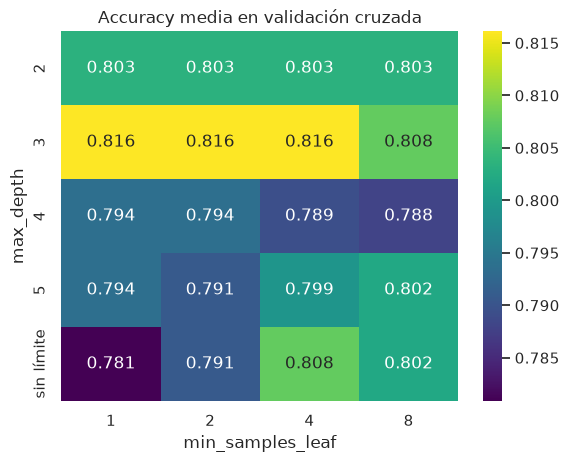

In [26]:
mejor = busqueda.best_params_
filtro = ((resultados["param_criterion"] == mejor["criterion"])
          & (resultados["param_min_samples_split"] == mejor["min_samples_split"]))

tabla = (resultados[filtro]
         .assign(max_depth=lambda d: d["param_max_depth"].map(lambda v: "sin límite" if pd.isna(v) else str(int(v))))
         .pivot_table(index="max_depth", columns="param_min_samples_leaf", values="mean_test_score"))

sns.heatmap(tabla, annot=True, fmt=".3f", cmap="viridis")
plt.title("Accuracy media en validación cruzada")
plt.xlabel("min_samples_leaf")
plt.ylabel("max_depth")
plt.show()

In [27]:
modelo_opt = busqueda.best_estimator_   # ya reentrenado con todo train

print("Profundidad:", modelo_opt.get_depth(), "| Hojas:", modelo_opt.get_n_leaves())
print("Accuracy en train:", accuracy_score(y_train, modelo_opt.predict(X_train)))
print("Accuracy en test: ", accuracy_score(y_test, modelo_opt.predict(X_test)))

Profundidad: 3 | Hojas: 8
Accuracy en train: 0.827247191011236
Accuracy en test:  0.8268156424581006


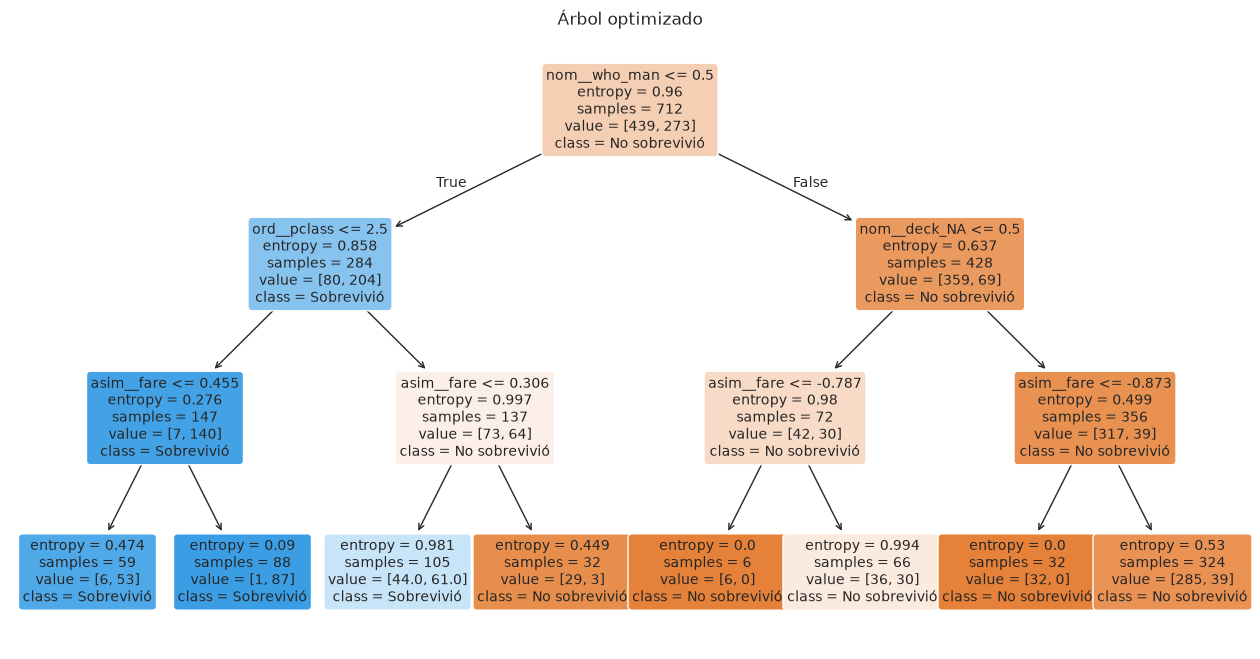

In [28]:
nombres = {0: "No sobrevivió", 1: "Sobrevivió"}

plt.figure(figsize=(16, 8))
plot_tree(
    modelo_opt,
    feature_names=list(X_train.columns),
    class_names=[nombres[c] for c in modelo_opt.classes_],
    filled=True, rounded=True, fontsize=10,
)
plt.title("Árbol optimizado")
plt.show()

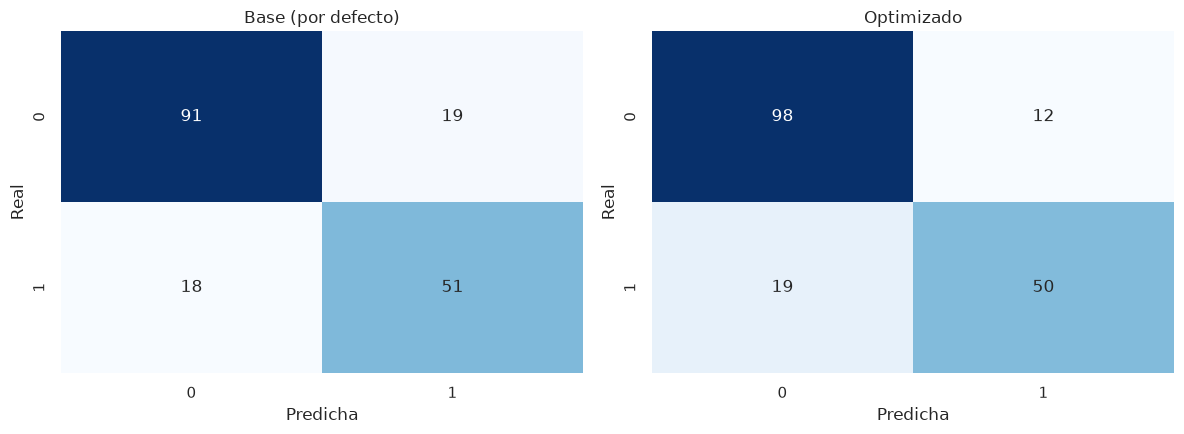

In [29]:
modelos = {"Base (por defecto)":arbol_base, "Optimizado": modelo_opt}
clases = arbol_base.classes_

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for (nombre, modelo), ax in zip(modelos.items(), axes):
    matriz = confusion_matrix(y_test, modelo.predict(X_test), labels=clases)
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=clases, yticklabels=clases, ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel("Predicha")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.show()